In [1]:
import pacmap
import umap.umap_                       as umap 
import numpy                            as np
import pandas                           as pd

import seaborn                          as sns
import matplotlib.pyplot                as plt
import matplotlib.gridspec              as gridspec
import plotly.express                   as px
import plotly.graph_objects             as go

from tqdm                               import tqdm
from plotly.subplots                    import make_subplots
from sklearn.preprocessing              import StandardScaler, MinMaxScaler
from sklearn.cluster                    import DBSCAN
from sklearn.mixture                    import GaussianMixture

from utils.Preprocessing2                import PreProcessData
from utils.plotFigures                  import plotResults, plotResultsPlotly, plotLabels, lineAndScatterPlot, scatterPlot2D
from clustering.plotClustering          import ClusteringResults

In [2]:
preData = PreProcessData()
df, scaled_data, df_healthy, scaled_healthy = preData.preprocessing(type_file        = 'h5', 
                                                                    scaler           = MinMaxScaler(), 
                                                                    window_size      = 6, 
                                                                    time_aggregation = '10min', 
                                                                    threshold        = 200)

# Plot time series colored by labels

In [3]:
# Each trajectory is divided into equal parts
def assign_labels(data, num_groups=2):
    n       = len(data)
    labels  = np.zeros(n, dtype=int)
    idx     = np.array_split(np.arange(n), num_groups)
    for i, group_idx in enumerate(idx):
        labels[group_idx] = i
    
    return labels

scaled_data['label'] = scaled_data.groupby('trajectory')['corriente(A)'].transform(assign_labels).astype('str')

In [4]:
plotLabels(dataframe    = scaled_data,
           variable     = preData.efficiency_cr1[0])

# Dimensionality Reduction

In [5]:
scaled_data['period']    = scaled_data['tiempo'].dt.strftime('%d-%m-%Y %H')
scaled_healthy['period'] = scaled_healthy['tiempo'].dt.strftime('%d-%m-%Y %H')

## Idea 1

In [6]:
# Embedding space using healthy data
columns = preData.efficiency_cr1+preData.new_efficiency_cr1
dfEfficiencyVar = scaled_healthy[columns] 

clusteringModels    = {'pacmap': DBSCAN(min_samples = 100,
                                        eps         = 5  )} 

dimReductionModels  = {'pacmap': pacmap.PaCMAP(n_components = 2, 
                                               random_state = 40, 
                                               save_tree    = True)}

EmbeddingHealthy = ClusteringResults(data                = scaled_healthy, 
                                     dataNormalized      = dfEfficiencyVar, 
                                     clusteringModels    = clusteringModels, 
                                     dimReductionModels  = dimReductionModels)

# Train dimensionality reduction model
EmbeddingHealthy.train()


# Embedding space for each trajectory
dfEfficiencyVar     = scaled_data[columns]
dimReductionModels  = EmbeddingHealthy.dimReductionModels

Embedding           = ClusteringResults(data                = scaled_data, 
                                        dataNormalized      = dfEfficiencyVar, 
                                        clusteringModels    = clusteringModels, 
                                        dimReductionModels  = dimReductionModels)

# Trained embedding space is used
Embedding.embedding = EmbeddingHealthy.embedding

# Get clusters
for trajectory in tqdm(Embedding.trajectories):
    Embedding.getResults(trajectory)

c:\Users\CAEX\Desktop\Diego\Crusher Project\2ndrealdatajournalchile\mmodal\Lib\site-packages\pacmap\pacmap.py:828: UserWarning:


100%|██████████| 24/24 [00:13<00:00,  1.79it/s]


## Idea 2

In [7]:
# Embedding space using labels 
dfEfficiencyVar = scaled_data[preData.efficiency_cr1 + preData.new_efficiency_cr1]

clusteringModels    = {'umap':   DBSCAN(min_samples = 100,
                                        eps         = 2)} 

dimReductionModels  = {'umap':   umap.UMAP(n_components = 2, 
                                           random_state = 40)}

SupervisedEmbedding = ClusteringResults(data                = scaled_data, 
                                        dataNormalized      = dfEfficiencyVar, 
                                        clusteringModels    = clusteringModels, 
                                        dimReductionModels  = dimReductionModels)

# Train dimensionality reduction model
SupervisedEmbedding.train(supervised=True)

for trajectory in tqdm(SupervisedEmbedding.trajectories):
    SupervisedEmbedding.getResults(trajectory)

c:\Users\CAEX\Desktop\Diego\Crusher Project\2ndrealdatajournalchile\mmodal\Lib\site-packages\umap\umap_.py:1945: UserWarning:

n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.

100%|██████████| 24/24 [00:34<00:00,  1.43s/it]


# Results

c:\Users\CAEX\Desktop\Diego\Crusher Project\2ndrealdatajournalchile\utils\plotFigures.py:179: RuntimeWarning:

More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.



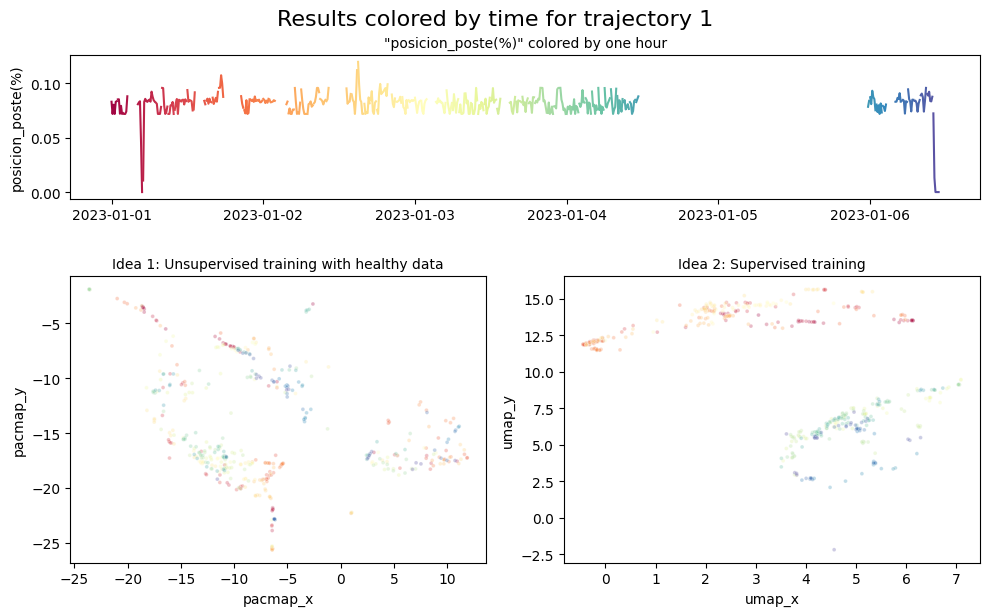

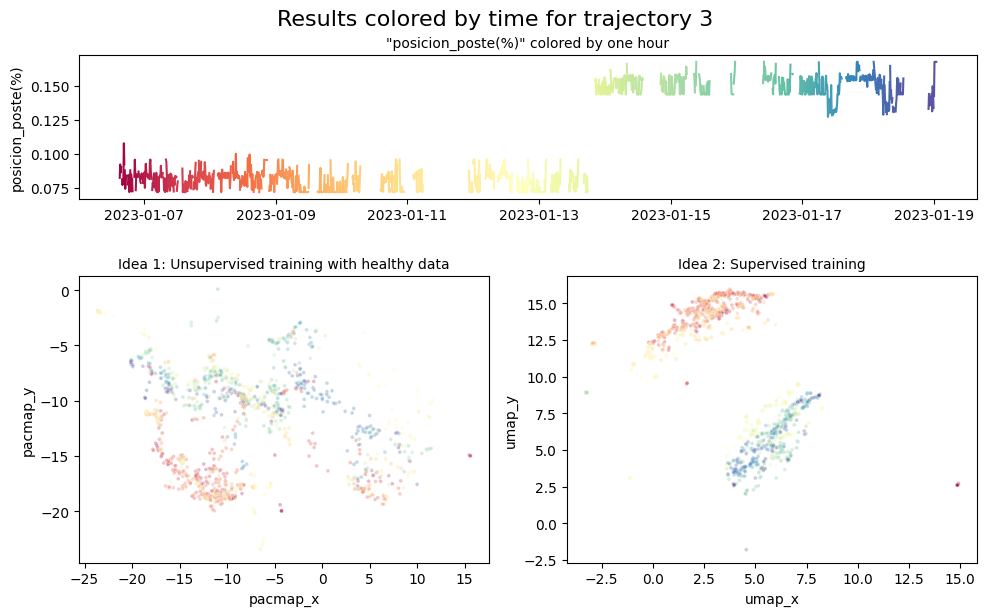

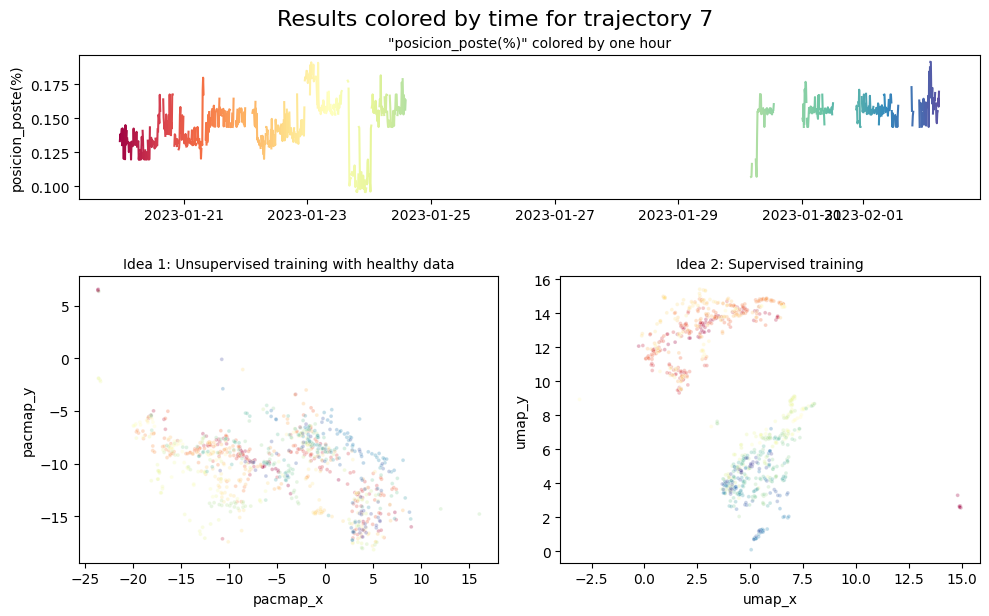

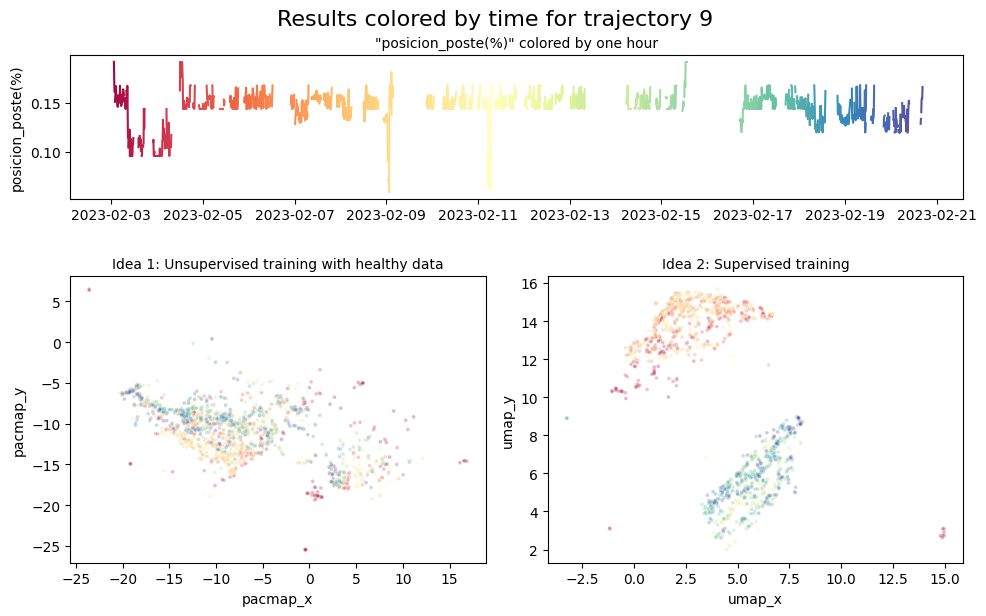

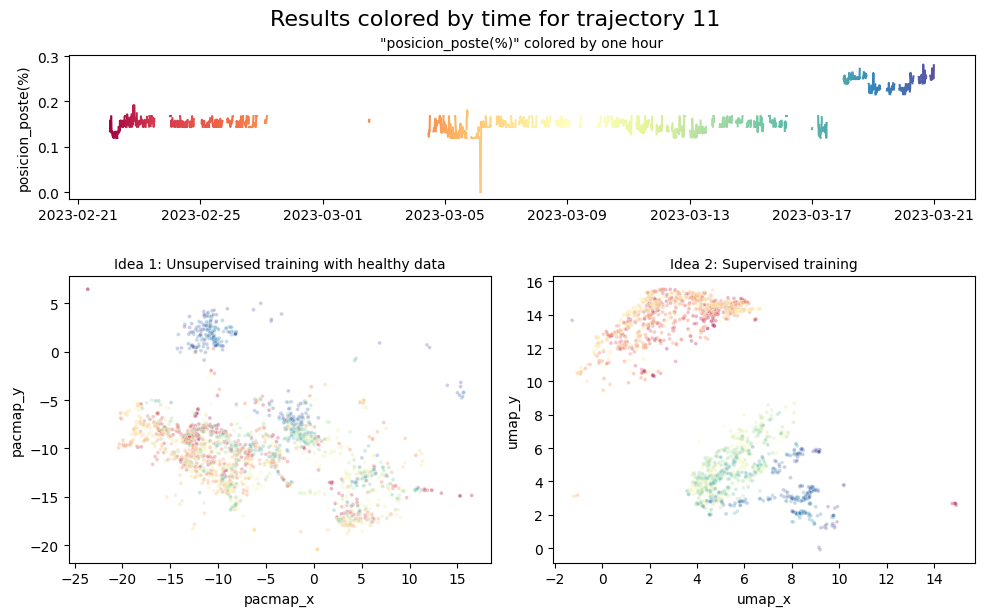

...

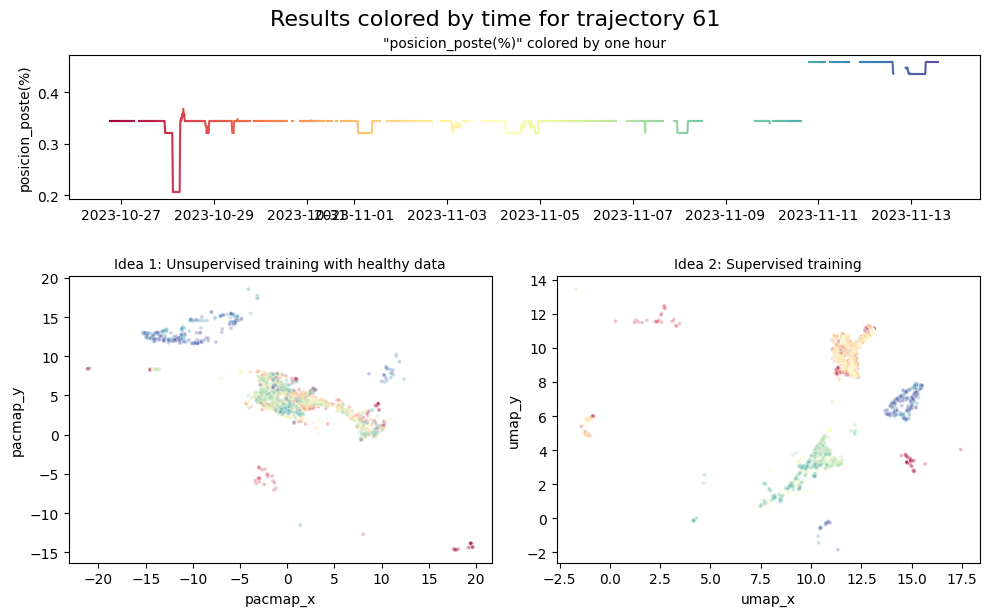

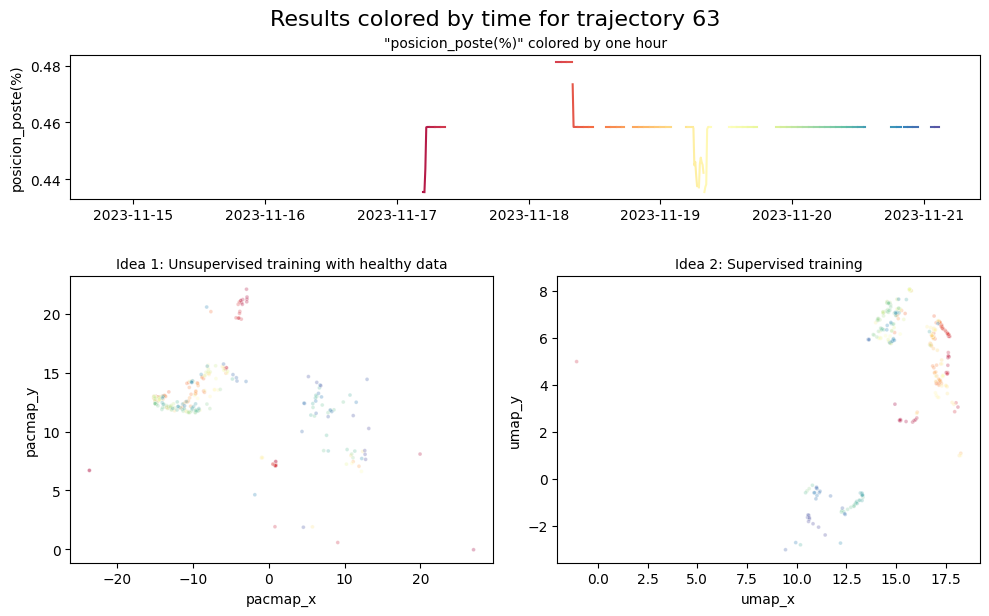

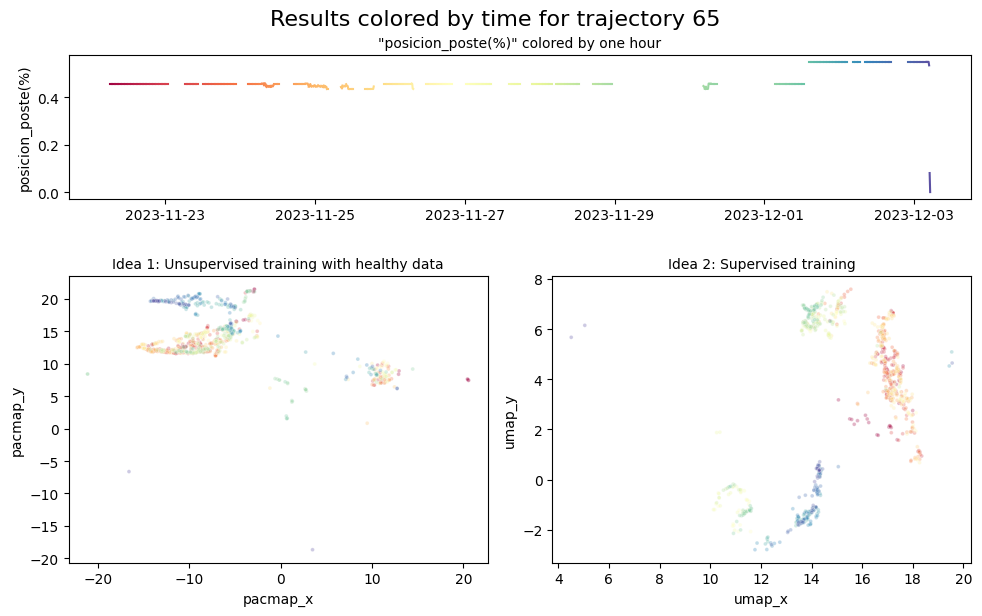

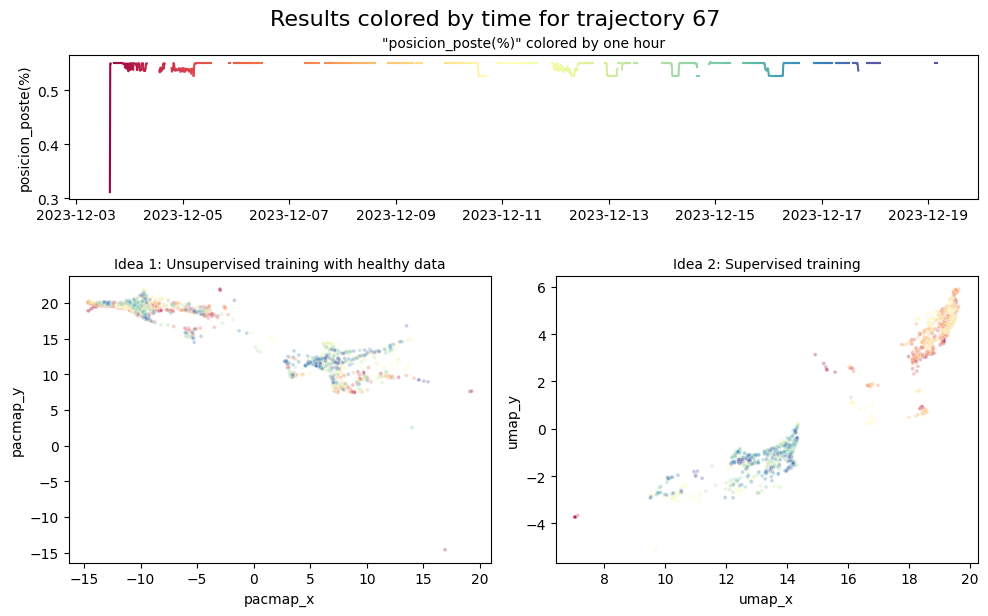

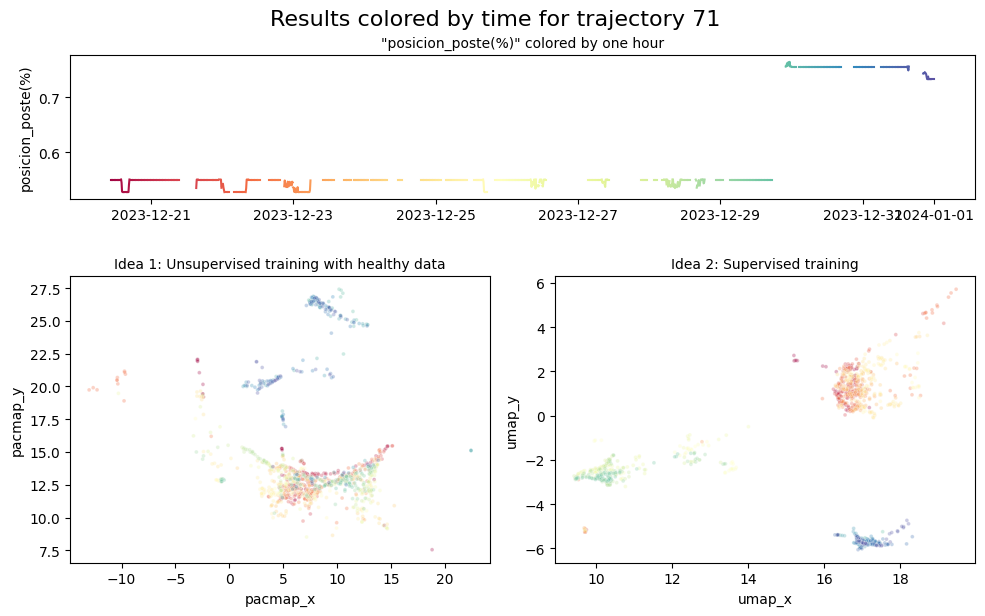

In [8]:
trajectories    = SupervisedEmbedding.trajectories
for trajectory in trajectories:
    # Dataframes
    data1       = Embedding.clustersResults[trajectory]
    data2       = SupervisedEmbedding.clustersResults[trajectory]
    plotResults(trajectory  = trajectory, 
                variable    = preData.efficiency_cr1[0],
                data1       = data1, 
                data2       = data2,
                algorithm_1 = 'pacmap',
                algorithm_2 = 'umap',
                palette     = 'Spectral')
    

## Plotly

In [9]:
trajectory  = '11'
data1       = Embedding.clustersResults[trajectory]
data2       = SupervisedEmbedding.clustersResults[trajectory]
plotResultsPlotly(trajectory    = trajectory, 
                  data1         = data1, 
                  data2         = data2,
                  variable      = preData.efficiency_cr1[0],
                  algorithm_1   = 'pacmap',
                  algorithm_2   = 'umap',
                  palette       = 'Spectral',
                  color         = 'period')

## Visualization of embedding space

In [10]:
supervised_efficiency_embedding = pd.concat(SupervisedEmbedding.clustersResults.values())
supervised_efficiency_embedding['label'] = scaled_data['label']
supervised_efficiency_embedding['trajectory'] = scaled_data['trajectory']

In [11]:
scatterPlot2D(data  = SupervisedEmbedding.embedding, 
              x     = f'umap_x', 
              y     = f'umap_y', 
              color = preData.efficiency_cr1[0])

In [12]:
scatterPlot2D(data  = supervised_efficiency_embedding, 
              x     = f'umap_x', 
              y     = f'umap_y', 
              color = 'label')